<a href="https://colab.research.google.com/github/LuisTT0903/Processamento-de-Sinais1/blob/main/Pratica7Quest%C3%A3o5a.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

(a) fs = 8192 Hz | potência de x = 0.03851
sigma^2 = 0.01: SNR de entrada = 4.35 dB
sigma^2 = 0.1: SNR de entrada = -4.33 dB
sigma^2 = 1.0: SNR de entrada = -14.18 dB


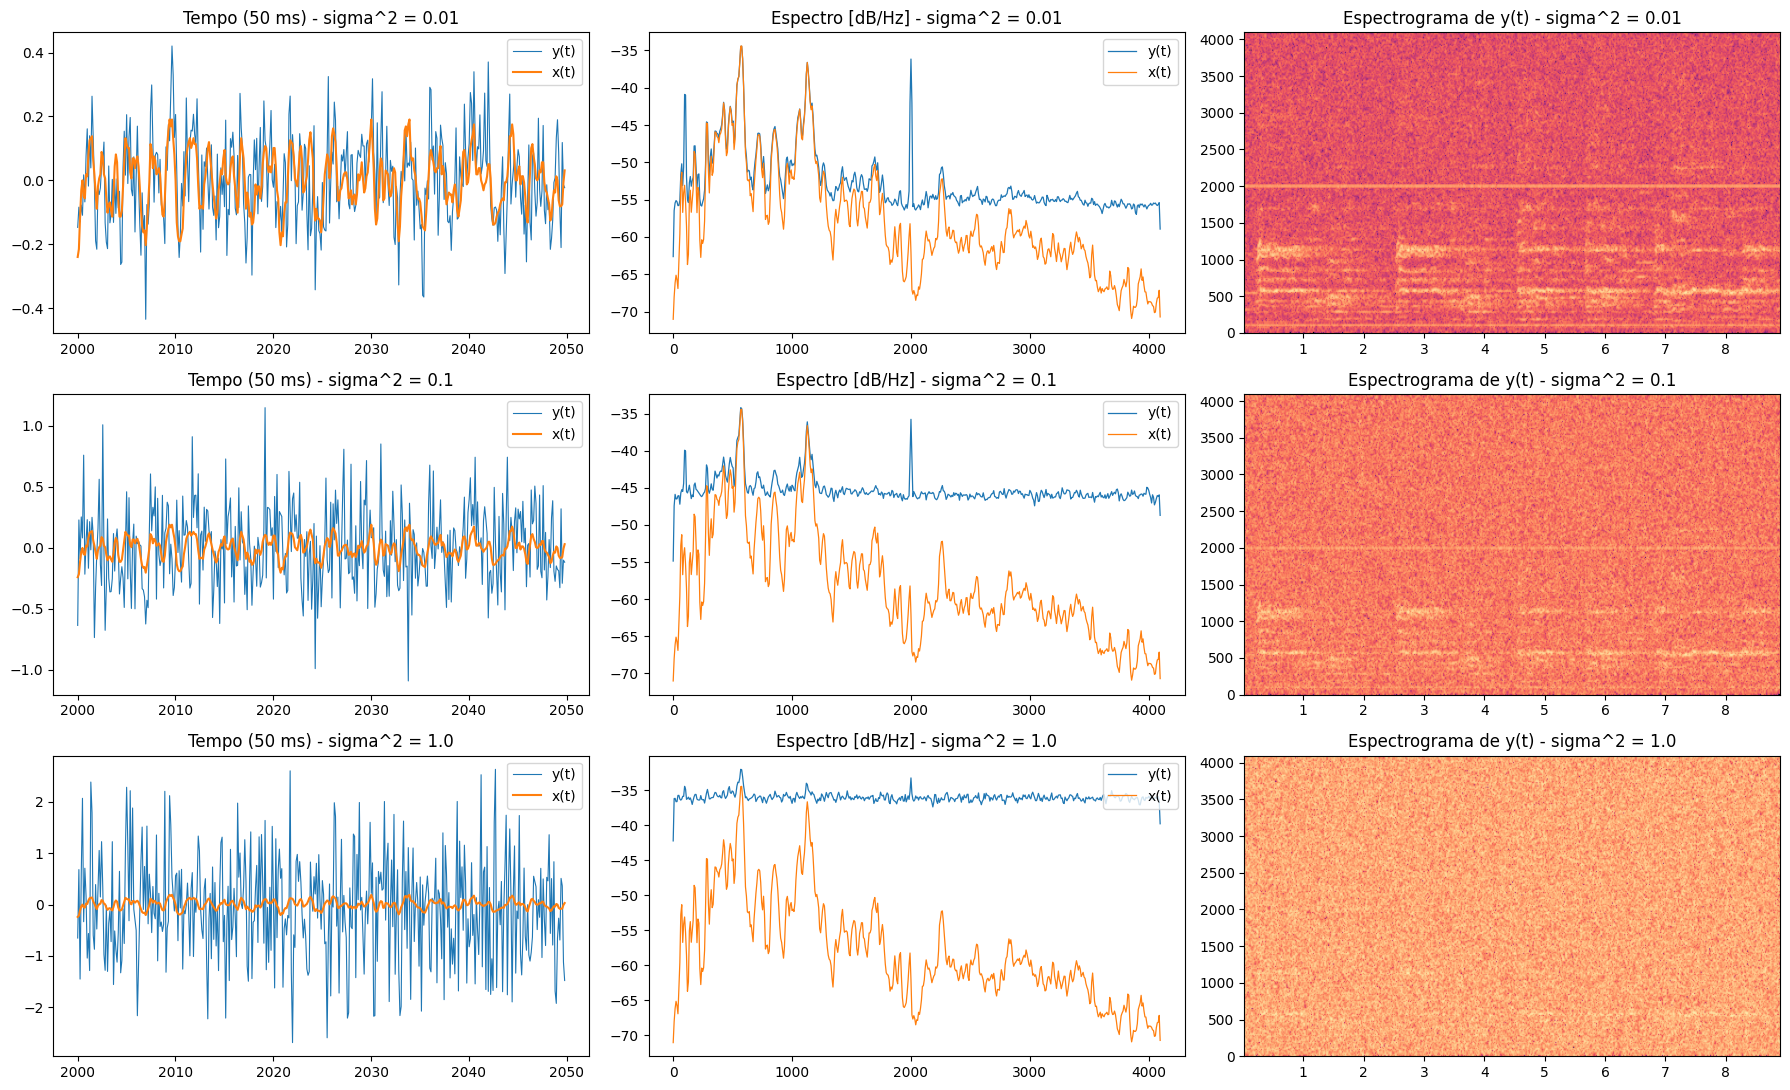

In [5]:
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

url = "https://raw.githubusercontent.com/LuisTT0903/Processamento-de-Sinais1/main/Aula_07/Audios_Usados/handel.wav"
if not os.path.exists("handel.wav"):
    urllib.request.urlretrieve(url, "handel.wav")
fs, x = wavfile.read("handel.wav")
x = x.astype(float) / 32768.0
N = len(x)
t = np.arange(N) / fs
interf = 0.05 * np.cos(200 * np.pi * t) + 0.075 * np.sin(4000 * np.pi * t)
variancias = [1e-2, 1e-1, 1.0]
rng = np.random.default_rng(0)
ruidos = {s2: np.sqrt(s2) * rng.standard_normal(N) for s2 in variancias}
ys = {s2: x + interf + ruidos[s2] for s2 in variancias}
pot = lambda v: np.mean(v ** 2)
psd = lambda v: (lambda f, P: (f, 10 * np.log10(P + 1e-20)))(*signal.welch(v, fs=fs, nperseg=1024))
n0, n1 = int(2.0 * fs), int(2.05 * fs)

print("(a) fs =", fs, "Hz | potência de x =", round(pot(x), 5))
fig, ax = plt.subplots(3, 3, figsize=(18, 11))
for k, s2 in enumerate(variancias):
    print(f"sigma^2 = {s2}: SNR de entrada = {10 * np.log10(pot(x) / pot(ys[s2] - x)):.2f} dB")
    ax[k, 0].plot(t[n0:n1] * 1000, ys[s2][n0:n1], lw=0.8, label="y(t)")
    ax[k, 0].plot(t[n0:n1] * 1000, x[n0:n1], lw=1.5, label="x(t)")
    ax[k, 1].plot(*psd(ys[s2]), lw=0.9, label="y(t)")
    ax[k, 1].plot(*psd(x), lw=0.9, label="x(t)")
    ax[k, 2].specgram(ys[s2], NFFT=512, Fs=fs, noverlap=384, cmap="magma", vmin=-120, vmax=-20)
    for j, tit in enumerate(["Tempo (50 ms)", "Espectro [dB/Hz]", "Espectrograma de y(t)"]):
        ax[k, j].set_title(f"{tit} - sigma^2 = {s2}")
    ax[k, 0].legend(loc="upper right")
    ax[k, 1].legend(loc="upper right")
fig.tight_layout()
plt.show()
display(Audio(x, rate=fs))
for s2 in variancias:
    display(Audio(ys[s2], rate=fs))

(a) A SNR de entrada é de 4,35 dB para sigma^2 = 0,01, -4,33 dB para 0,1 e -14,18 dB para 1. Com 0,01 a forma de onda original ainda é reconhecível. Com 0,1 e 1 o ruído domina, porque seu desvio padrão é maior que o valor RMS do sinal (0,196). No espectro, as interferências aparecem como raias em 100 Hz e 2000 Hz sobre um patamar plano de ruído. Ao ouvir, percebe-se um zumbido grave, um apito agudo e um chiado. Com sigma^2 = 1 a música fica quase mascarada.
